In [83]:
import numpy as np 
import matplotlib.pyplot as plt 
import matplotlib as mpl
import pandas as pd

data = pd.read_csv("./data/group_2.csv", delimiter=",")
plt.rcParams['text.usetex'] = False # Enables LaTeX
plt.rcParams['figure.dpi'] = 300 # Generates HD Graphs


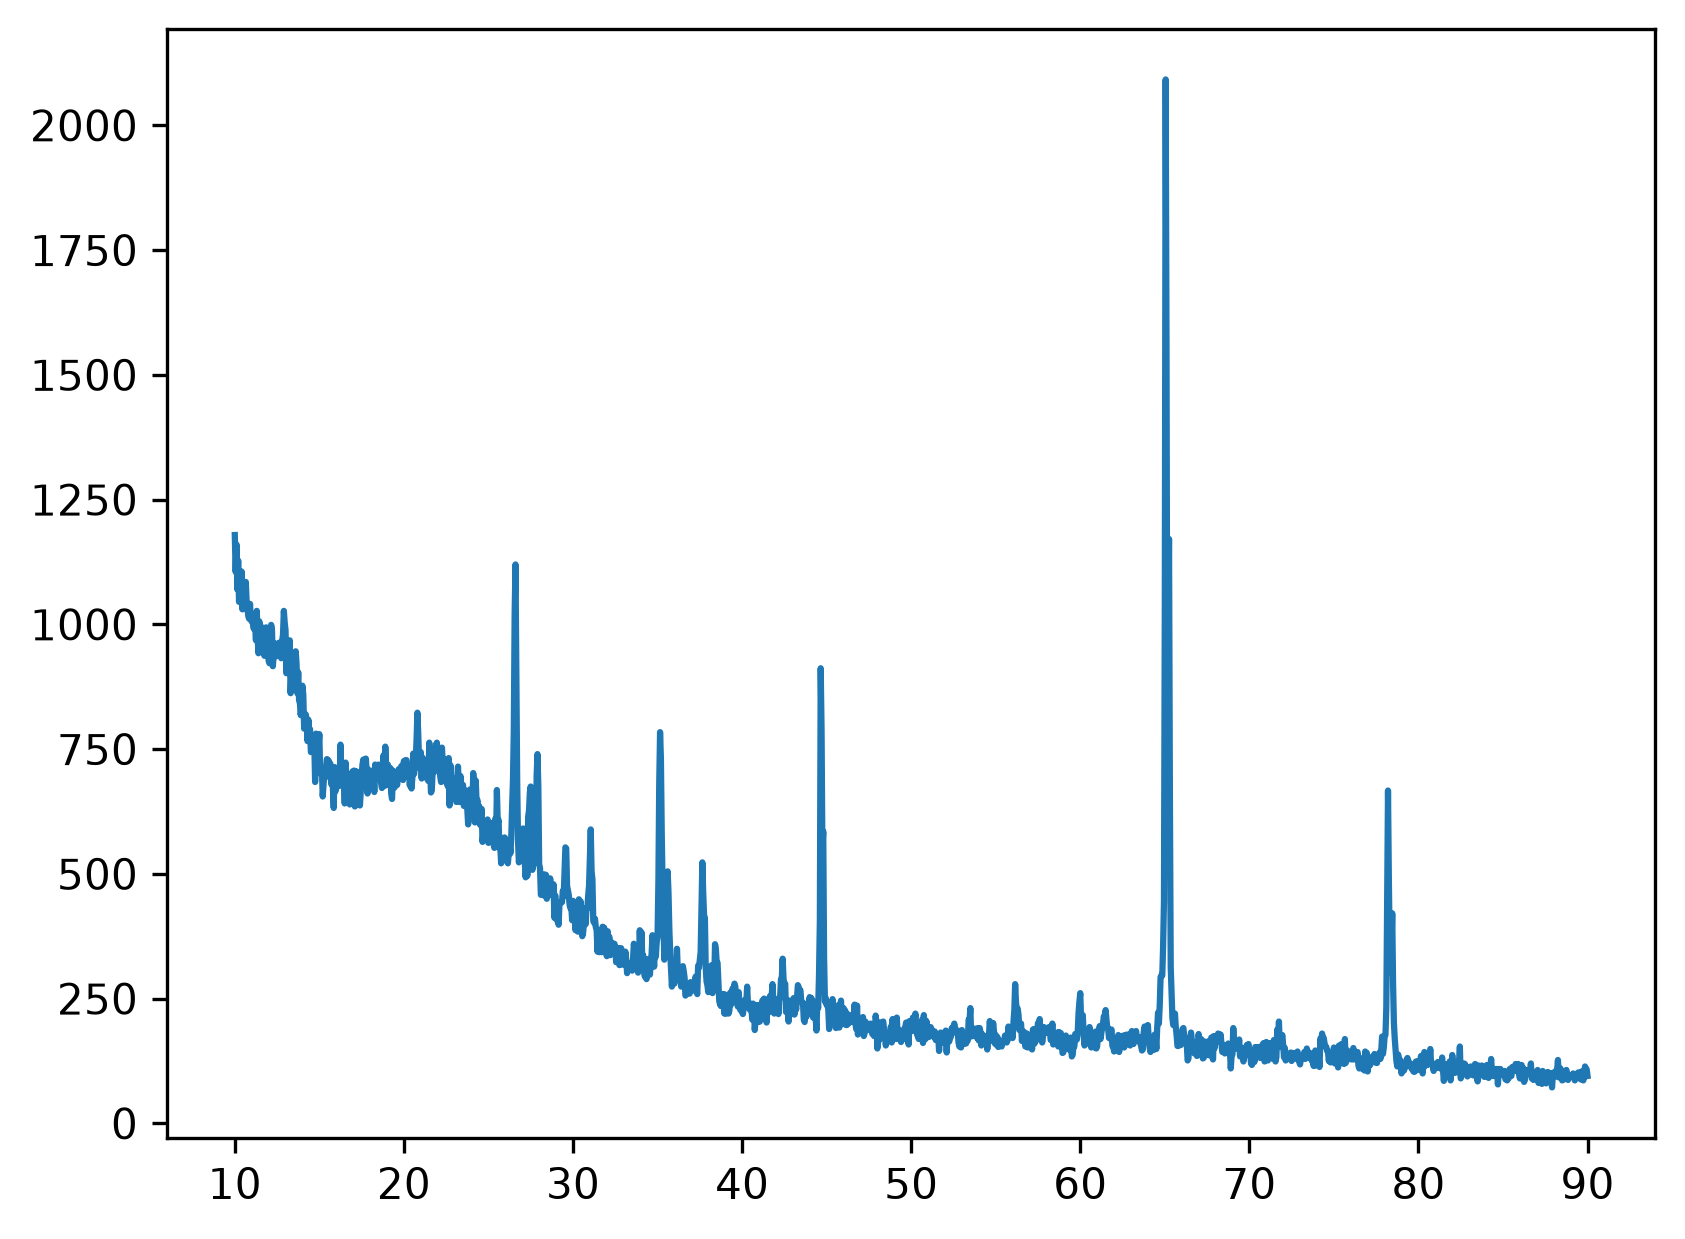

In [84]:
plt.plot(data["two_theta"], data['intensity'])

In [27]:
def plot_xrd_against_mp(
    exp_file_path: str,
    api_key: str,
    chemsys: list[str] = ["Al", "Fe", "Si-O", "Al-Fe"],
    two_theta_range: tuple[float, float] = (10, 90),
    wavelength: str = "CuKa",
    energy_above_hull_cutoff: float = 0.01,
    save_cifs_dir: str = "cif_files"
):
    """
    Pulls structures from Materials Project, saves CIFs, simulates XRD patterns,
    and plots them against experimental XRD data.
    
    Parameters:
    - exp_file_path: Path to experimental 2-column (2theta, intensity) data file (.xy, .csv, .txt).
    - api_key: Your Materials Project API key (from next-gen.materialsproject.org).
    - chemsys: List of chemical systems to query (e.g., ["Al", "Fe", "Al-Fe", "Si-O"]).
    - two_theta_range: Tuple of (min_2theta, max_2theta).
    - wavelength: X-ray radiation source (default 'CuKa' = 1.54184 Å).
    - energy_above_hull_cutoff: Max energy above hull (eV/atom) to filter out unstable polymorphs.
    - save_cifs_dir: Directory to save the downloaded CIF files.
    """
    
    # 1. Load Experimental Data
    # Assumes a 2-column file (2theta, intensity). Adjust 'sep' and 'skiprows' for your specific instrument output.
    try:
        exp_data = pd.read_csv(exp_file_path, sep=',', engine='python', comment='#', header=None)
        # Drop any non-numeric header rows if present
        exp_data = exp_data.apply(pd.to_numeric, errors='coerce').dropna()
        exp_2theta = exp_data.iloc[:, 0].values
        exp_intensity = exp_data.iloc[:, 1].values
    except Exception as e:
        raise ValueError(f"Error reading experimental file: {e}. Check delimiter and header lines.")

    # Filter experimental data to the specified 2-theta range and normalize to 100
    mask = (exp_2theta >= two_theta_range[0]) & (exp_2theta <= two_theta_range[1])
    exp_2theta = exp_2theta[mask]
    exp_intensity = exp_intensity[mask]
    exp_intensity_norm = (exp_intensity / np.max(exp_intensity)) * 100

    # 2. Query Materials Project and Save CIFs
    os.makedirs(save_cifs_dir, exist_ok=True)
    structures = {}
    
    with MPRester(api_key) as mpr:
        for sys in chemsys:
            docs = mpr.materials.summary.search(
                chemsys=sys,
                energy_above_hull=(0, energy_above_hull_cutoff),
                theoretical = False,
                fields=["material_id", "formula_pretty", "structure", "energy_above_hull"]
            )
            for doc in docs:
                label = f"{doc.formula_pretty} ({doc.material_id})"
                structures[label] = doc.structure
                
                # Save CIF file locally
                cif_path = os.path.join(save_cifs_dir, f"{doc.formula_pretty}_{doc.material_id}.cif")
                doc.structure.to(filename=cif_path)
                
    print(f"Downloaded {len(structures)} stable phases and saved CIFs to '{save_cifs_dir}/'.")

    # 3. Initialize XRD Calculator and Plot Setup
    calculator = XRDCalculator(wavelength=wavelength)
    
    num_refs = len(structures)
    fig, axes = plt.subplots(
        nrows=num_refs + 1, 
        ncols=1, 
        figsize=(10, 2.5 + 1.2 * num_refs), 
        sharex=True,
        gridspec_kw={'height_ratios': [3] + [1] * num_refs}
    )
    
    if num_refs == 0:
        axes = [axes]

    # 4. Plot Experimental Spectrum (Top Panel)
    ax_exp = axes[0]
    ax_exp.plot(exp_2theta, exp_intensity_norm, color='black', lw=1.2, label='Experimental Sample (Al-Fe + SiO2)')
    ax_exp.set_ylabel("Normalized Intensity (a.u.)")
    ax_exp.set_title("Experimental XRD vs. Materials Project Reference Phases")
    ax_exp.legend(loc="upper right")
    ax_exp.grid(axis='x', linestyle='--', alpha=0.5)

    # 5. Calculate and Plot Simulated Reference Stick Patterns
    cmap = mpl.colormaps.get_cmap('tab10')
    
    for idx, (label, struct) in enumerate(structures.items()):
        ax_ref = axes[idx + 1]
        pattern = calculator.get_pattern(struct, two_theta_range=two_theta_range)
        
        # Plot sticks for reference peaks
        ax_ref.vlines(pattern.x, 0, pattern.y, color=cmap(idx), lw=1.5, label=label)
        
        # Also plot vertical guide lines up into the experimental plot for top 3 strongest peaks
        top_peaks_idx = np.argsort(pattern.y)[-5:]
        for peak_i in top_peaks_idx:
            ax_exp.axvline(pattern.x[peak_i], color=cmap(idx), linestyle=':', alpha=0.4, lw=1)

        ax_ref.set_ylim(0, 110)
        ax_ref.set_yticks([])
        ax_ref.legend(loc="upper right", frameon=False, fontsize=9)
        ax_ref.grid(axis='x', linestyle='--', alpha=0.5)

    axes[-1].set_xlabel(r"$2\theta$ (degrees)")
    axes[-1].set_xlim(two_theta_range)
    plt.tight_layout()
    plt.subplots_adjust(hspace=0.08)
    plt.show()

Retrieving SummaryDoc documents:   0%|          | 0/3 [00:00<?, ?it/s]

Retrieving SummaryDoc documents:   0%|          | 0/5 [00:00<?, ?it/s]

Retrieving SummaryDoc documents:   0%|          | 0/6 [00:00<?, ?it/s]

Downloaded 14 stable phases and saved CIFs to 'cif_files/'.


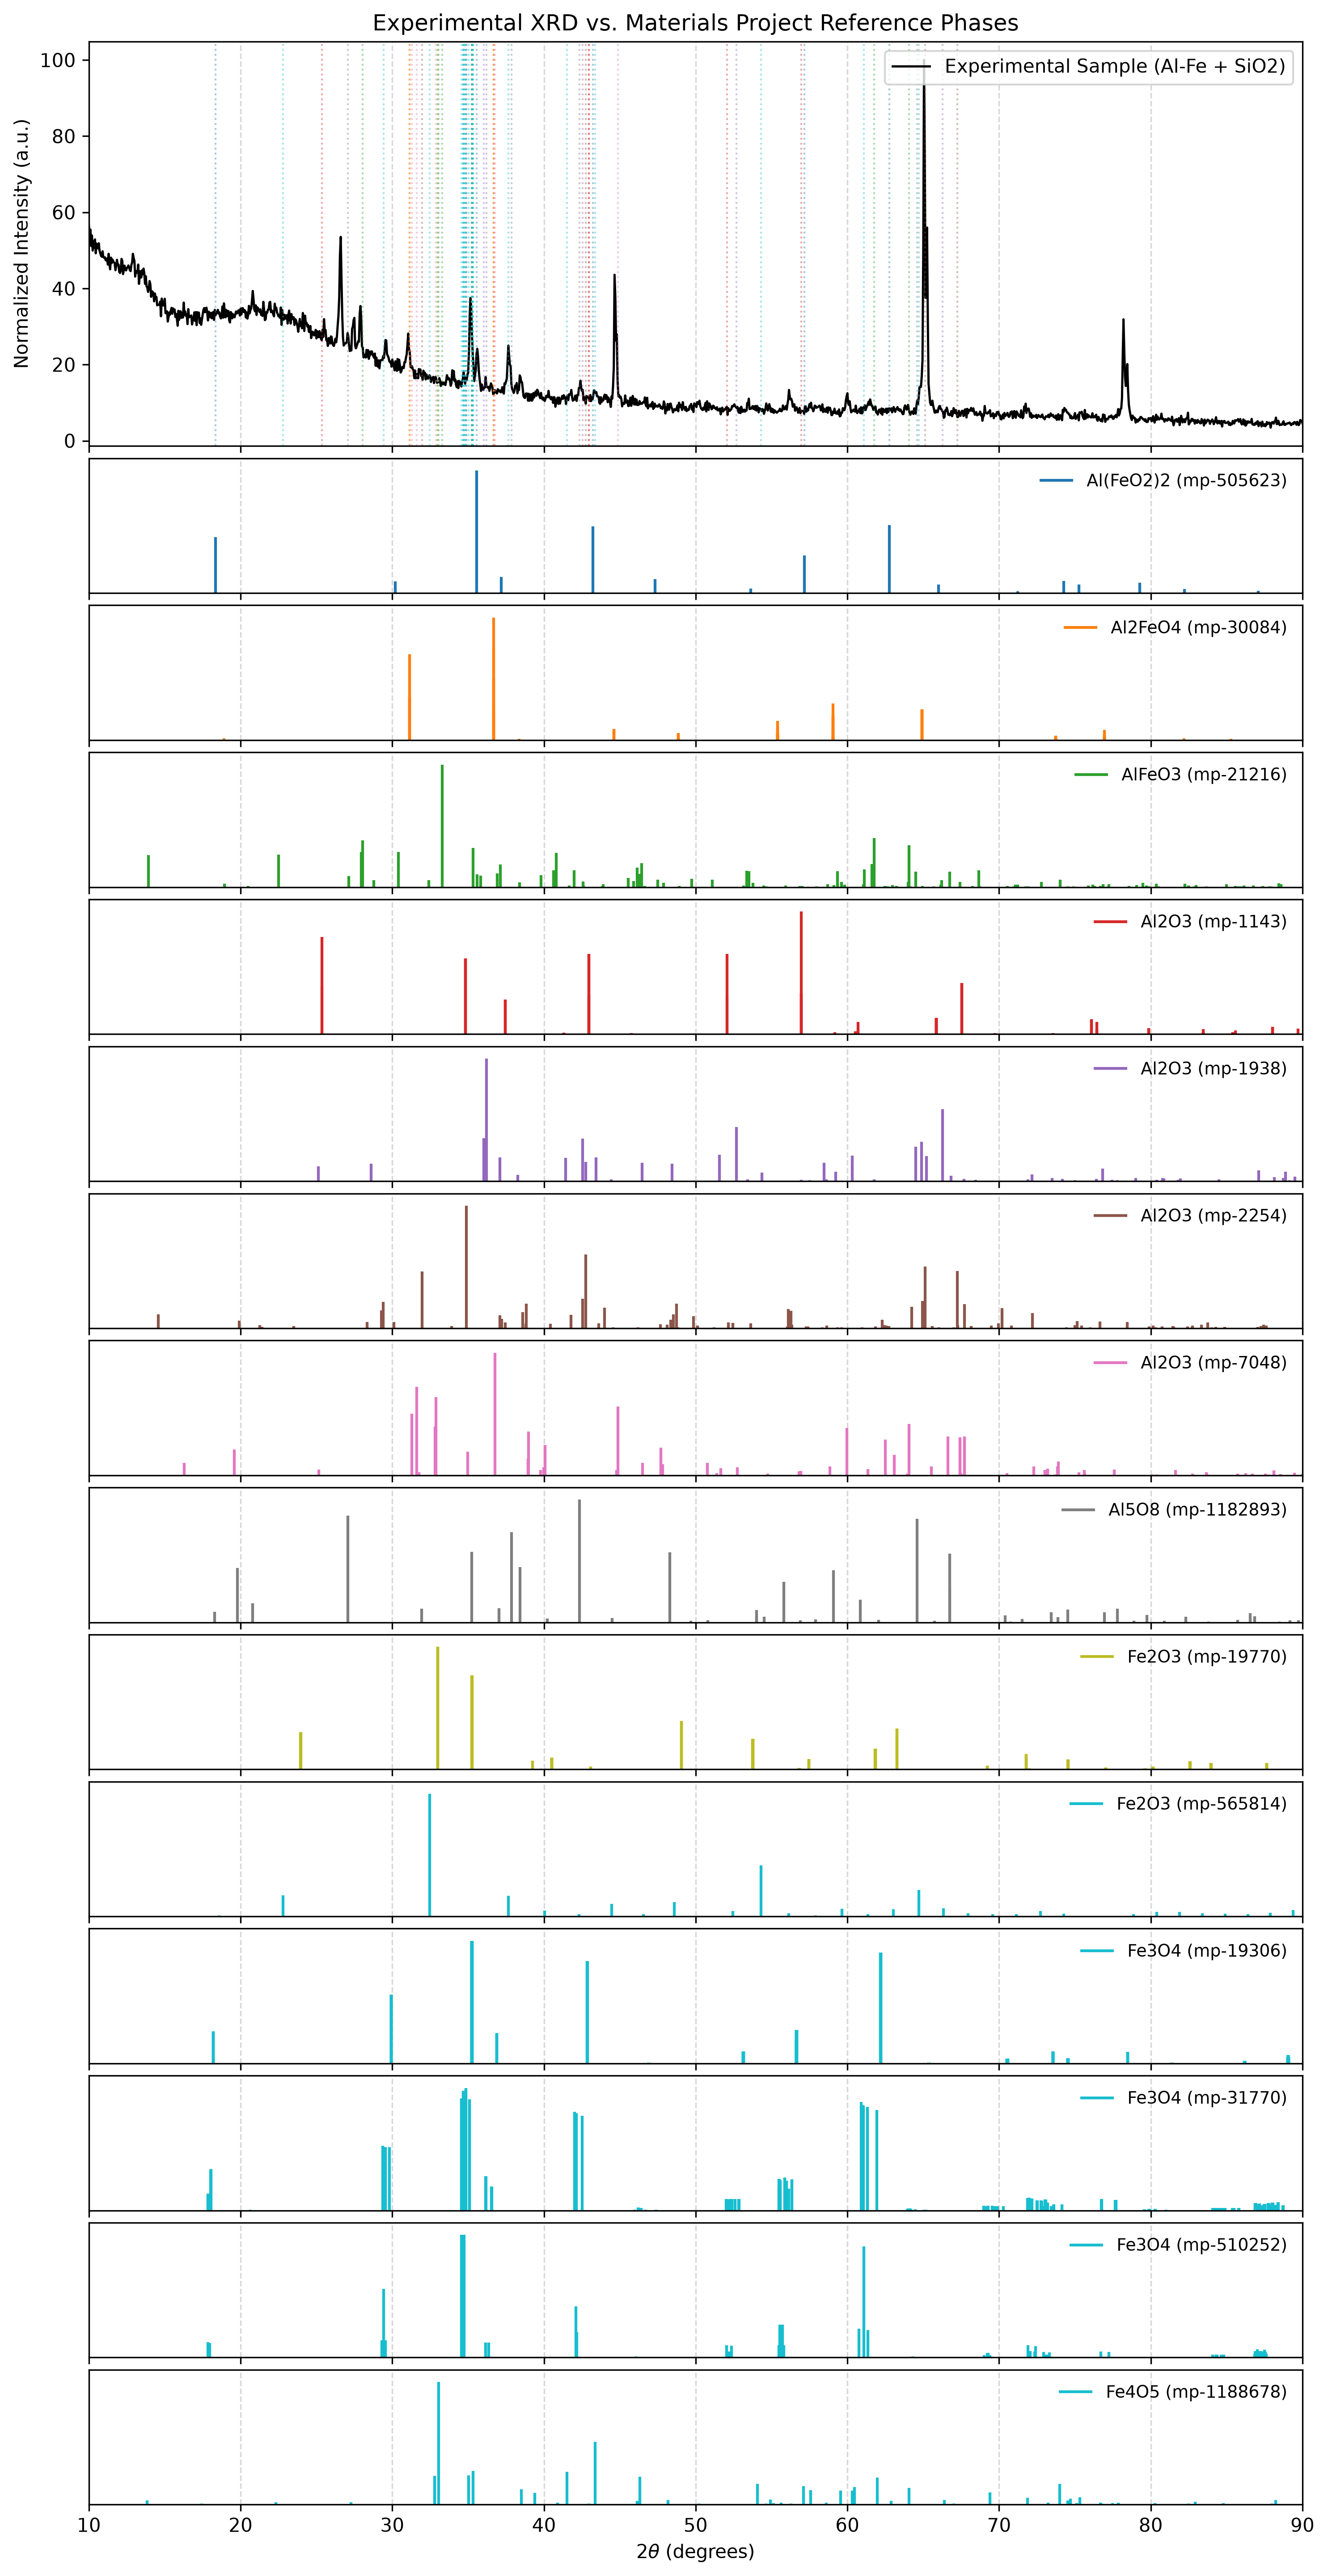

In [85]:
import os
from mp_api.client import MPRester
from pymatgen.analysis.diffraction.xrd import XRDCalculator
MY_MP_API_KEY = os.getenv("API_KEY")
plot_xrd_against_mp(exp_file_path='./data/group_2.csv', api_key=MY_MP_API_KEY, chemsys=['Al-Fe-O', 'Al-O', 'Fe-O'], energy_above_hull_cutoff=0.1)

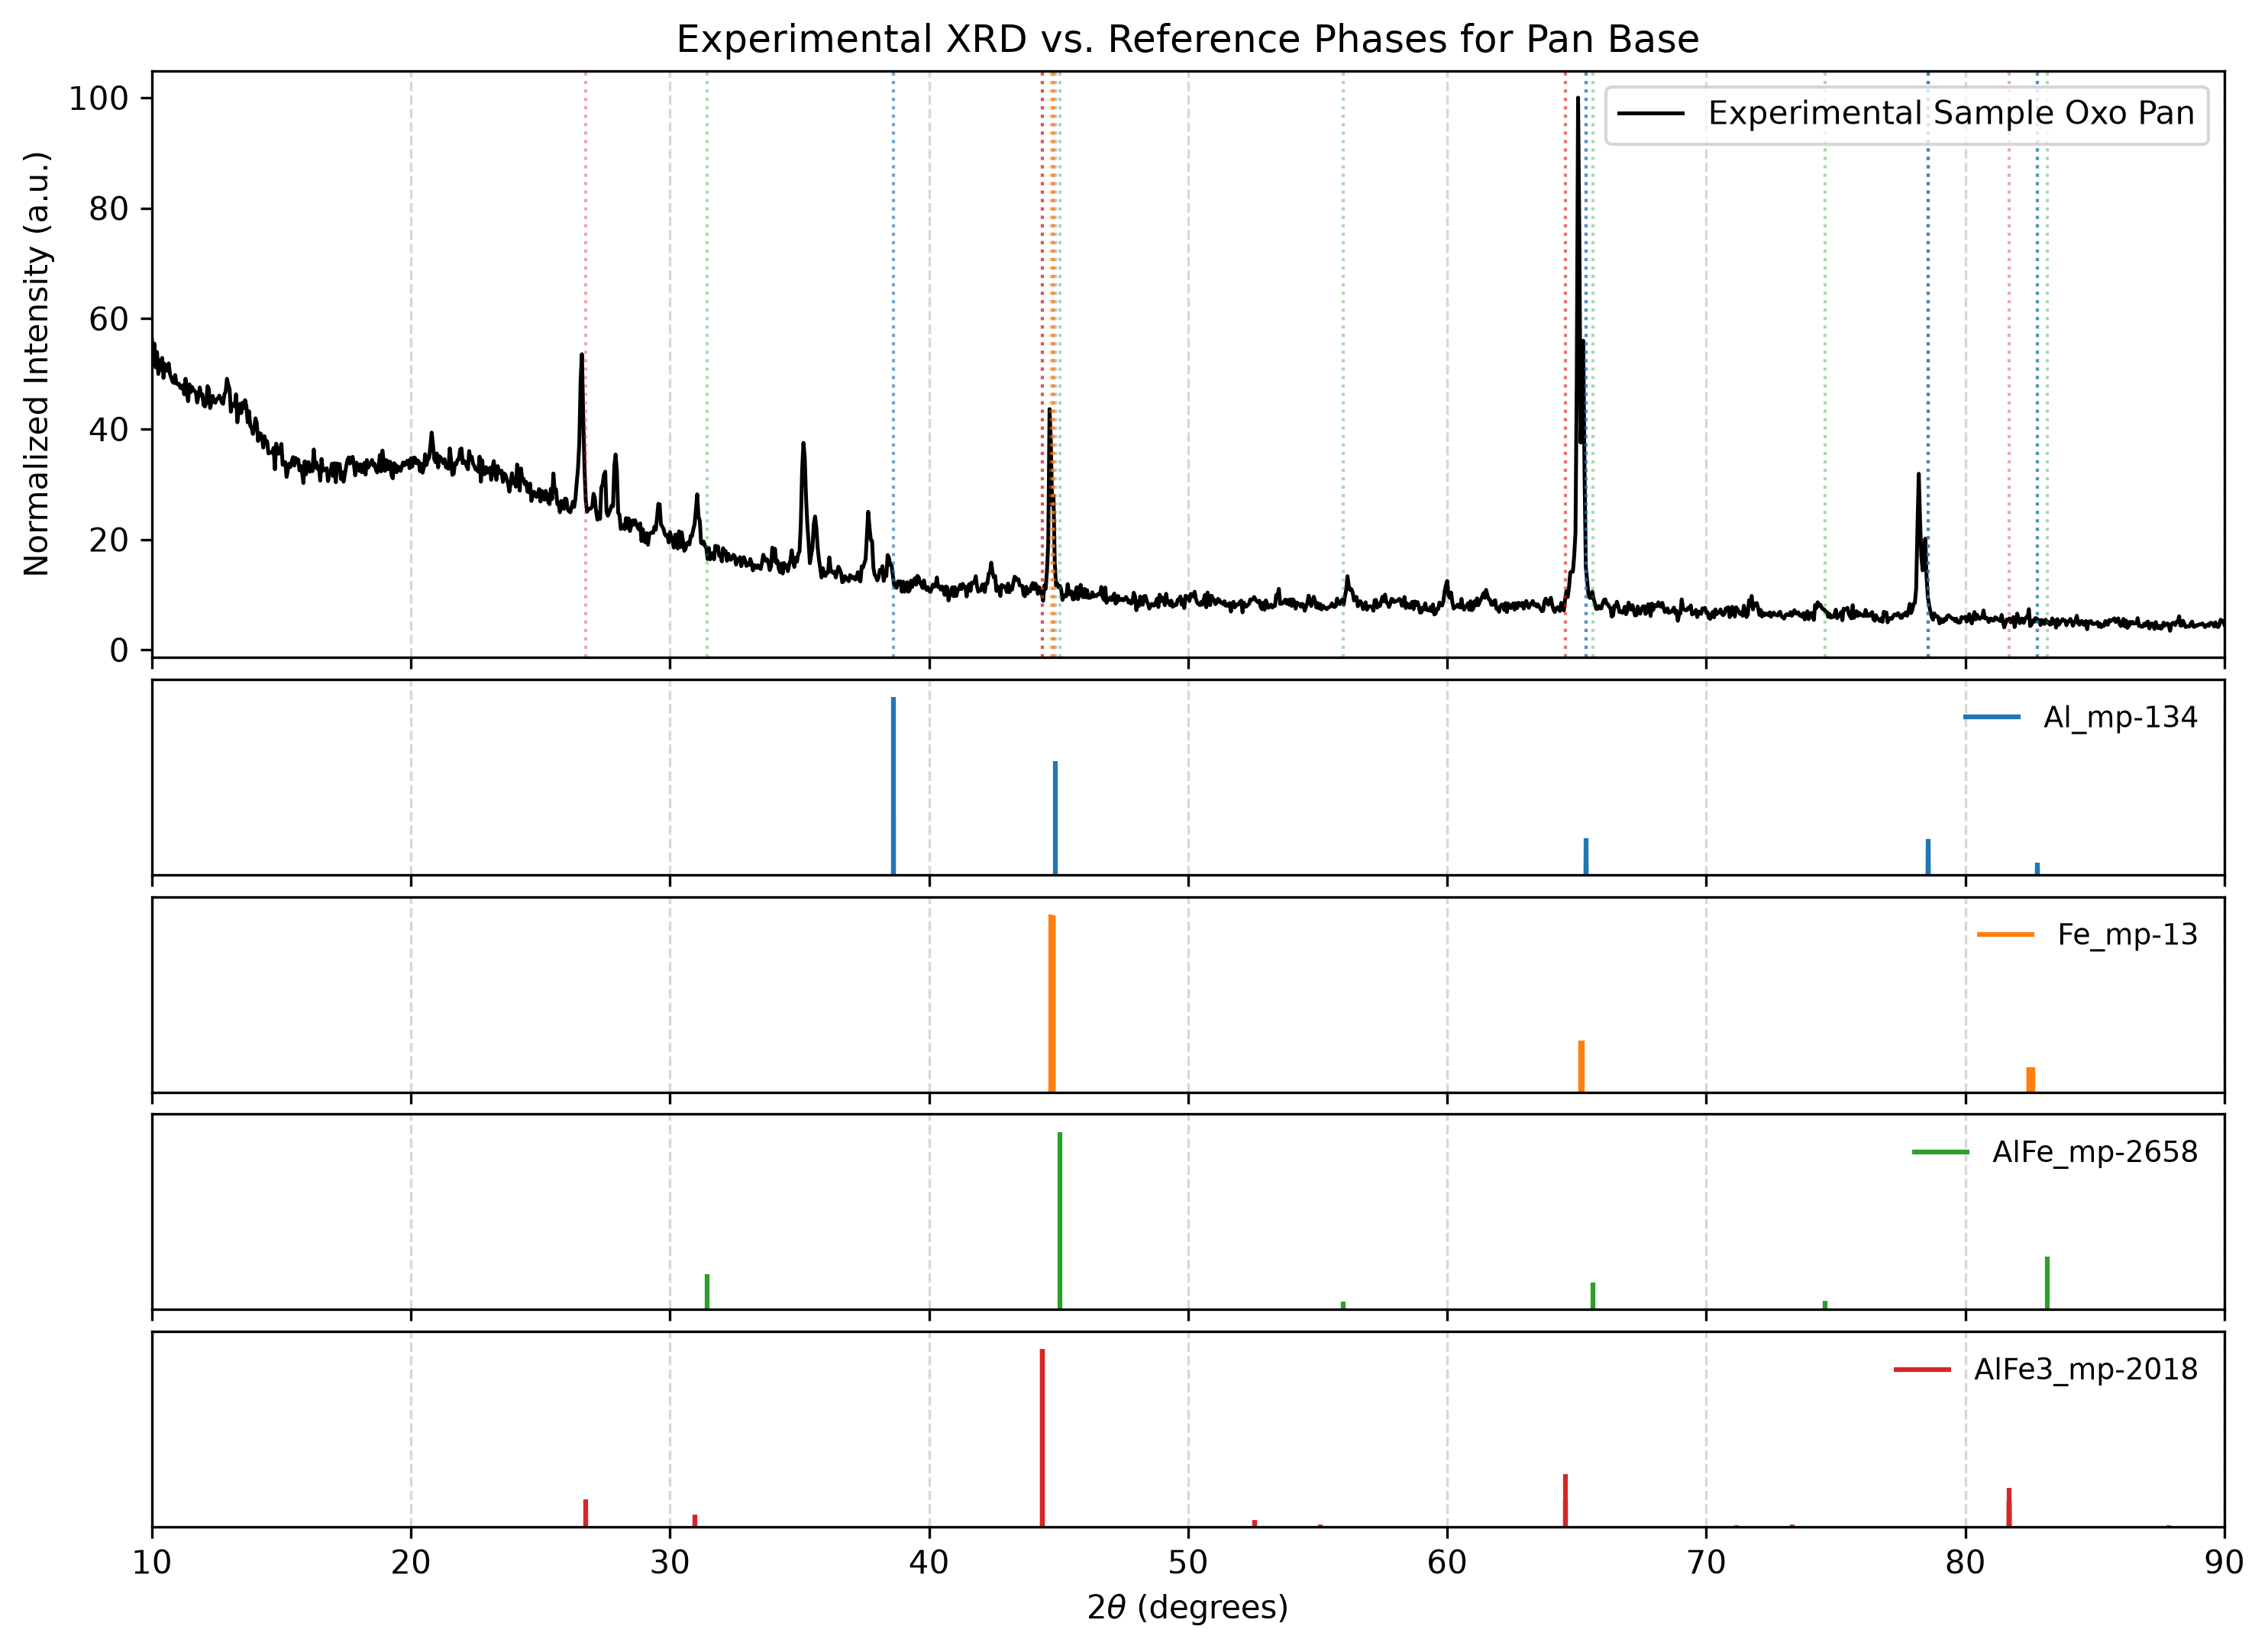

In [86]:
import glob
from pymatgen.core import Structure
from pymatgen.analysis.diffraction.xrd import XRDCalculator
import math

dir = './cif_files/base/'

def plot_from_dir (folder, title, pct=0.2):
    cifs = glob.glob(folder+'*.cif')
    structures = {}

    for file in cifs:
        structures[file[:-4].replace(folder, '')] = Structure.from_file(file)
    calculator = XRDCalculator(wavelength="CuKa")

    two_theta_range=(10,90
                    )
    try:
        exp_data = data
        # Drop any non-numeric header rows if present
        exp_data = exp_data.apply(pd.to_numeric, errors='coerce').dropna()
        exp_2theta = exp_data.iloc[:, 0].values
        exp_intensity = exp_data.iloc[:, 1].values
    except Exception as e:
        raise ValueError(f"Error reading experimental file: {e}. Check delimiter and header lines.")

    # Filter experimental data to the specified 2-theta range and normalize to 100
    mask = (exp_2theta >= two_theta_range[0]) & (exp_2theta <= two_theta_range[1])
    exp_2theta = exp_2theta[mask]
    exp_intensity = exp_intensity[mask]
    exp_intensity_norm = (exp_intensity / np.max(exp_intensity)) * 100

    num_refs = len(structures)
    fig, axes = plt.subplots(
        nrows=num_refs + 1, 
        ncols=1, 
        figsize=(10, 2.5 + 1.2 * num_refs), 
        sharex=True,
        gridspec_kw={'height_ratios': [3] + [1] * num_refs}
    )

    if num_refs == 0:
        axes = [axes]

    # 4. Plot Experimental Spectrum (Top Panel)
    ax_exp = axes[0]
    ax_exp.plot(exp_2theta, exp_intensity_norm, color='black', lw=1.2, label='Experimental Sample Oxo Pan')
    ax_exp.set_ylabel("Normalized Intensity (a.u.)")
    ax_exp.set_title(title)
    ax_exp.legend(loc="upper right")
    ax_exp.grid(axis='x', linestyle='--', alpha=0.5)

    # 5. Calculate and Plot Simulated Reference Stick Patterns
    cmap = mpl.colormaps.get_cmap('tab10')

    for idx, (label, struct) in enumerate(structures.items()):
        ax_ref = axes[idx + 1]
        pattern = calculator.get_pattern(struct, two_theta_range=two_theta_range)
        
        # Plot sticks for reference peaks
        ax_ref.vlines(pattern.x, 0, pattern.y, color=cmap(idx), lw=1.5, label=label)
        
        # Also plot vertical guide lines up into the experimental plot for top 5 strongest peaks
        if len(pattern.y) > 15:
            k = math.ceil(len(pattern.y)*pct)
            top_peaks_idx = np.argsort(pattern.y)[-k:]
        else:
            top_peaks_idx = np.argsort(pattern.y)
        for peak_i in top_peaks_idx:
            ax_exp.axvline(pattern.x[peak_i], color=cmap(idx), linestyle=':', alpha=0.4, lw=1)

        ax_ref.set_ylim(0, 110)
        ax_ref.set_yticks([])
        ax_ref.legend(loc="upper right", frameon=False, fontsize=9)
        ax_ref.grid(axis='x', linestyle='--', alpha=0.5)

    axes[-1].set_xlabel(r"$2\theta$ (degrees)")
    axes[-1].set_xlim(two_theta_range)
    plt.tight_layout()
    plt.subplots_adjust(hspace=0.08)
    plt.show()

plot_from_dir(dir, "Experimental XRD vs. Reference Phases for Pan Base")

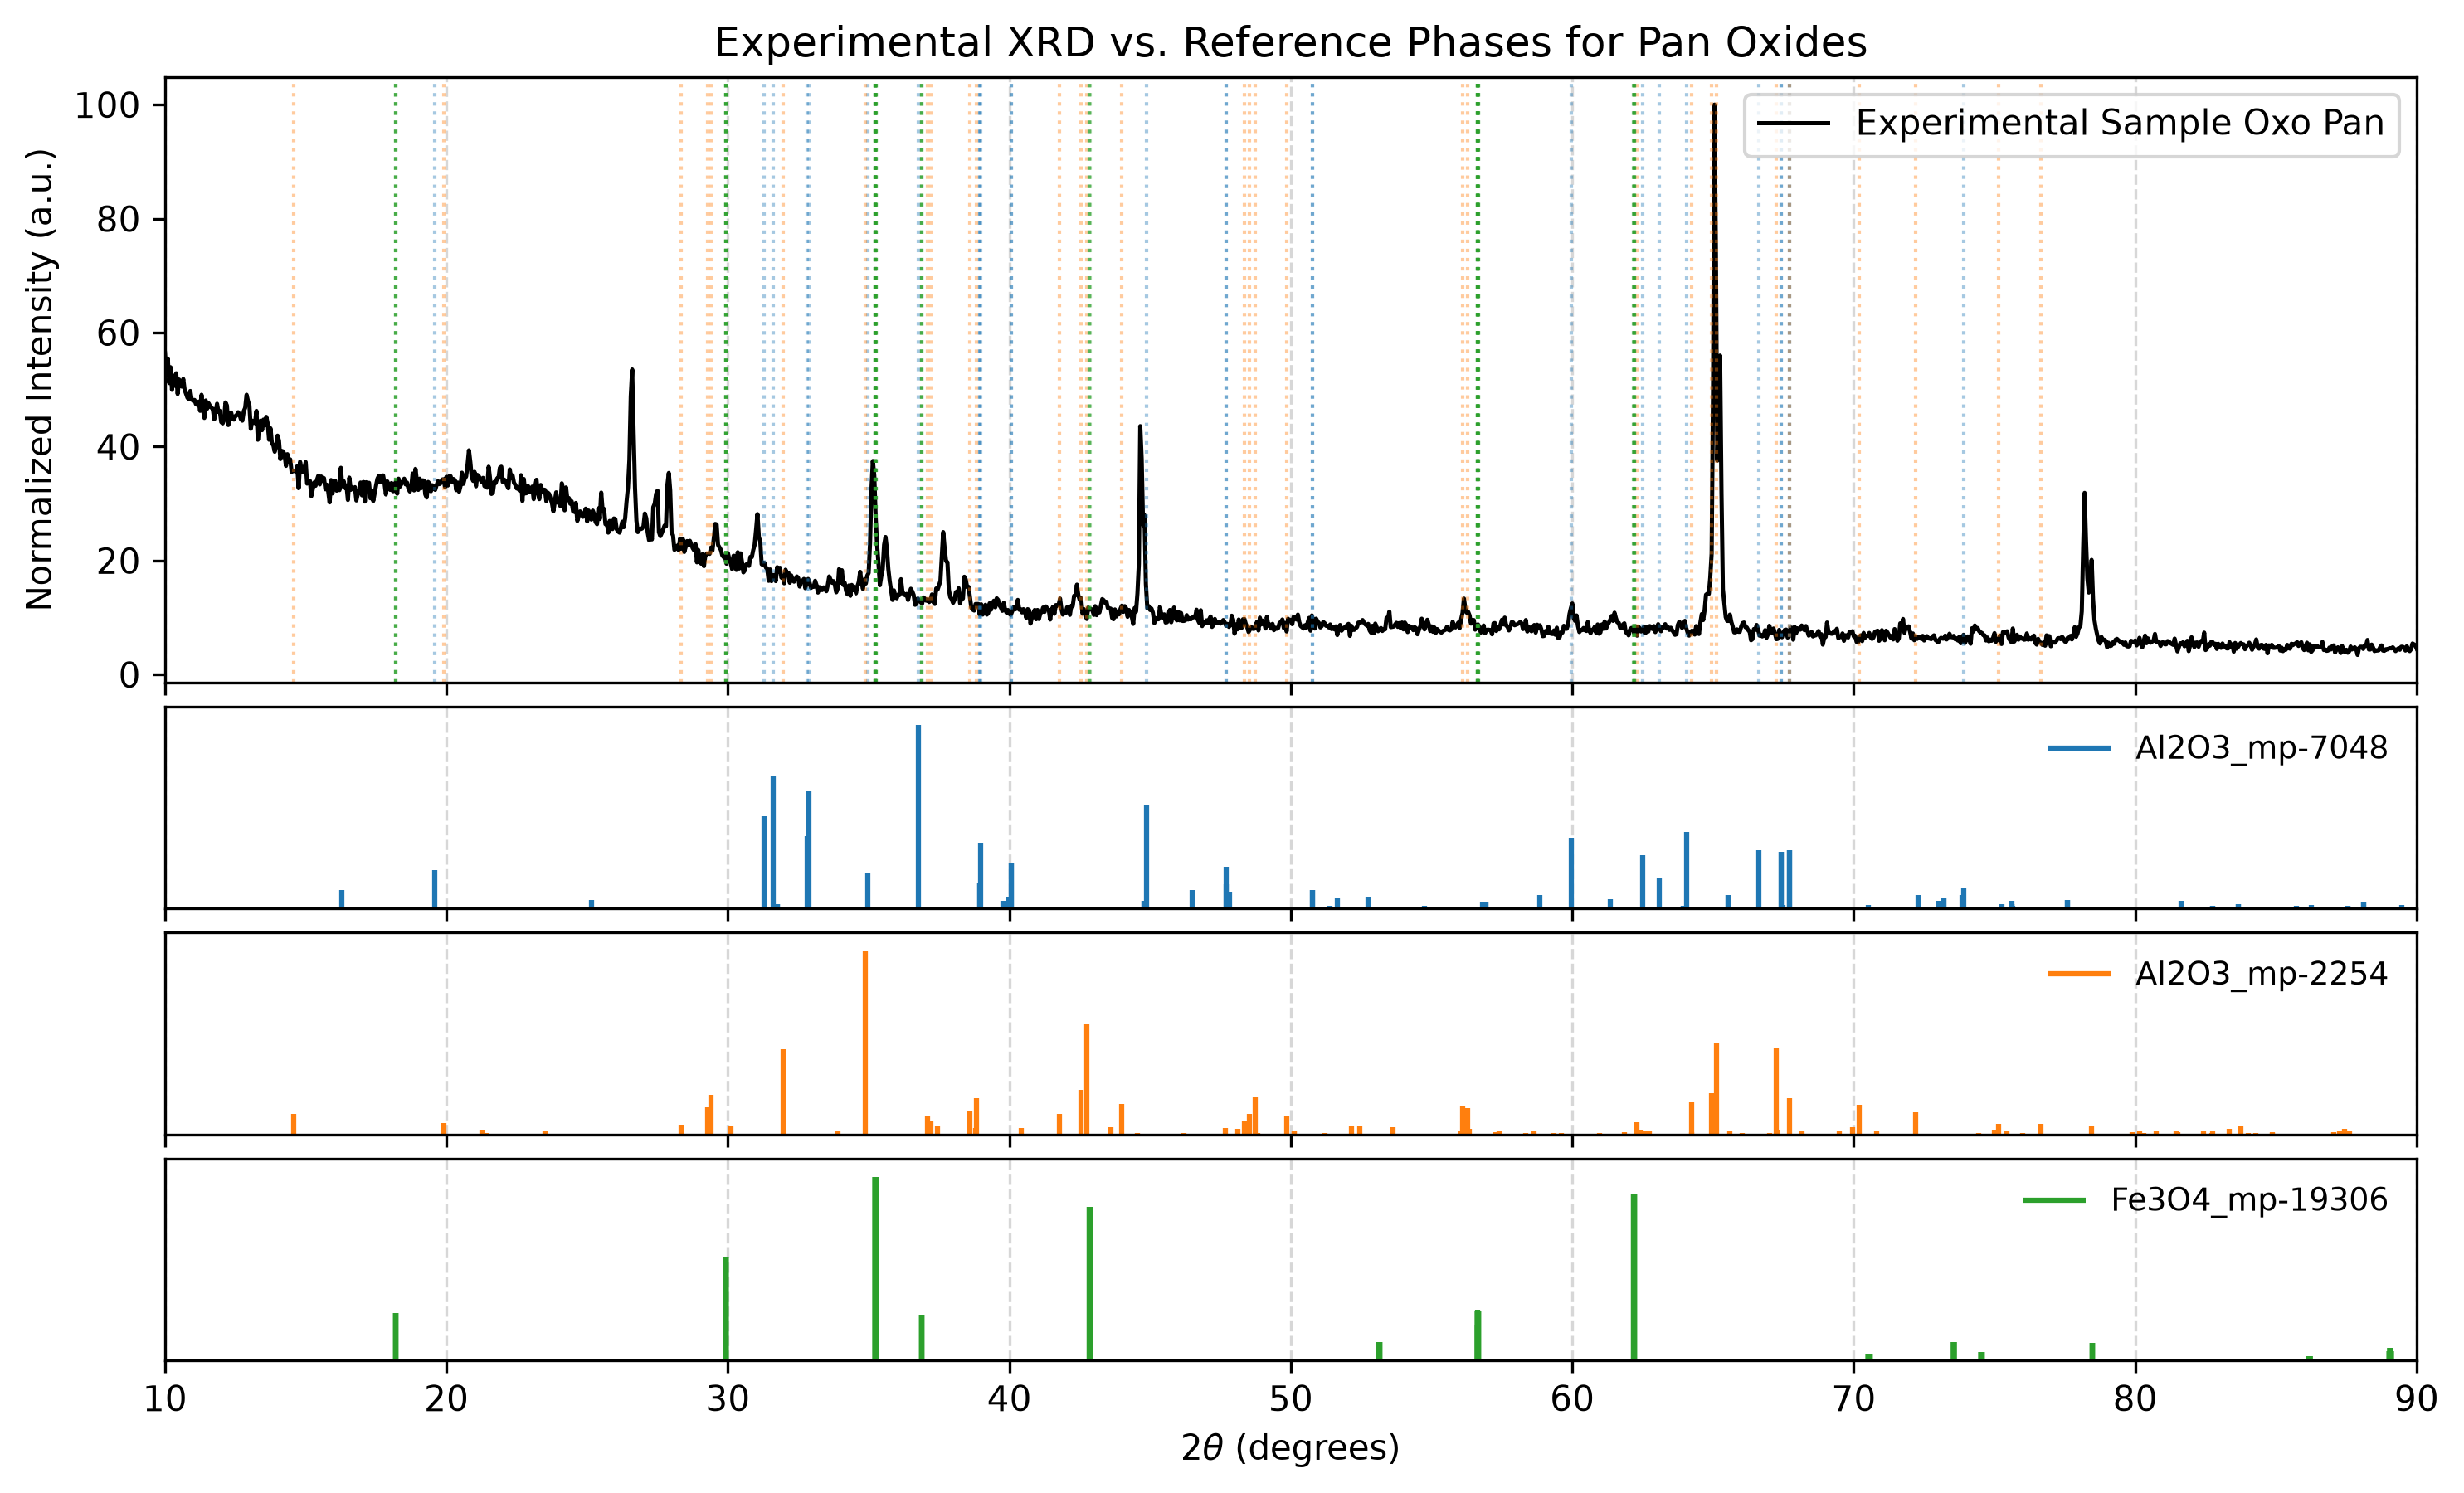

In [87]:
plot_from_dir('./cif_files/oxides/', "Experimental XRD vs. Reference Phases for Pan Oxides")

/home/mhtoon/.conda/envs/MSE164L/lib/python3.15/site-packages/pymatgen/io/cif.py:1817: UserWarning: Issues encountered while parsing CIF: 2 fractional coordinates rounded to ideal values to avoid issues with finite precision.
  return parser.parse_structures(primitive=primitive)[0]


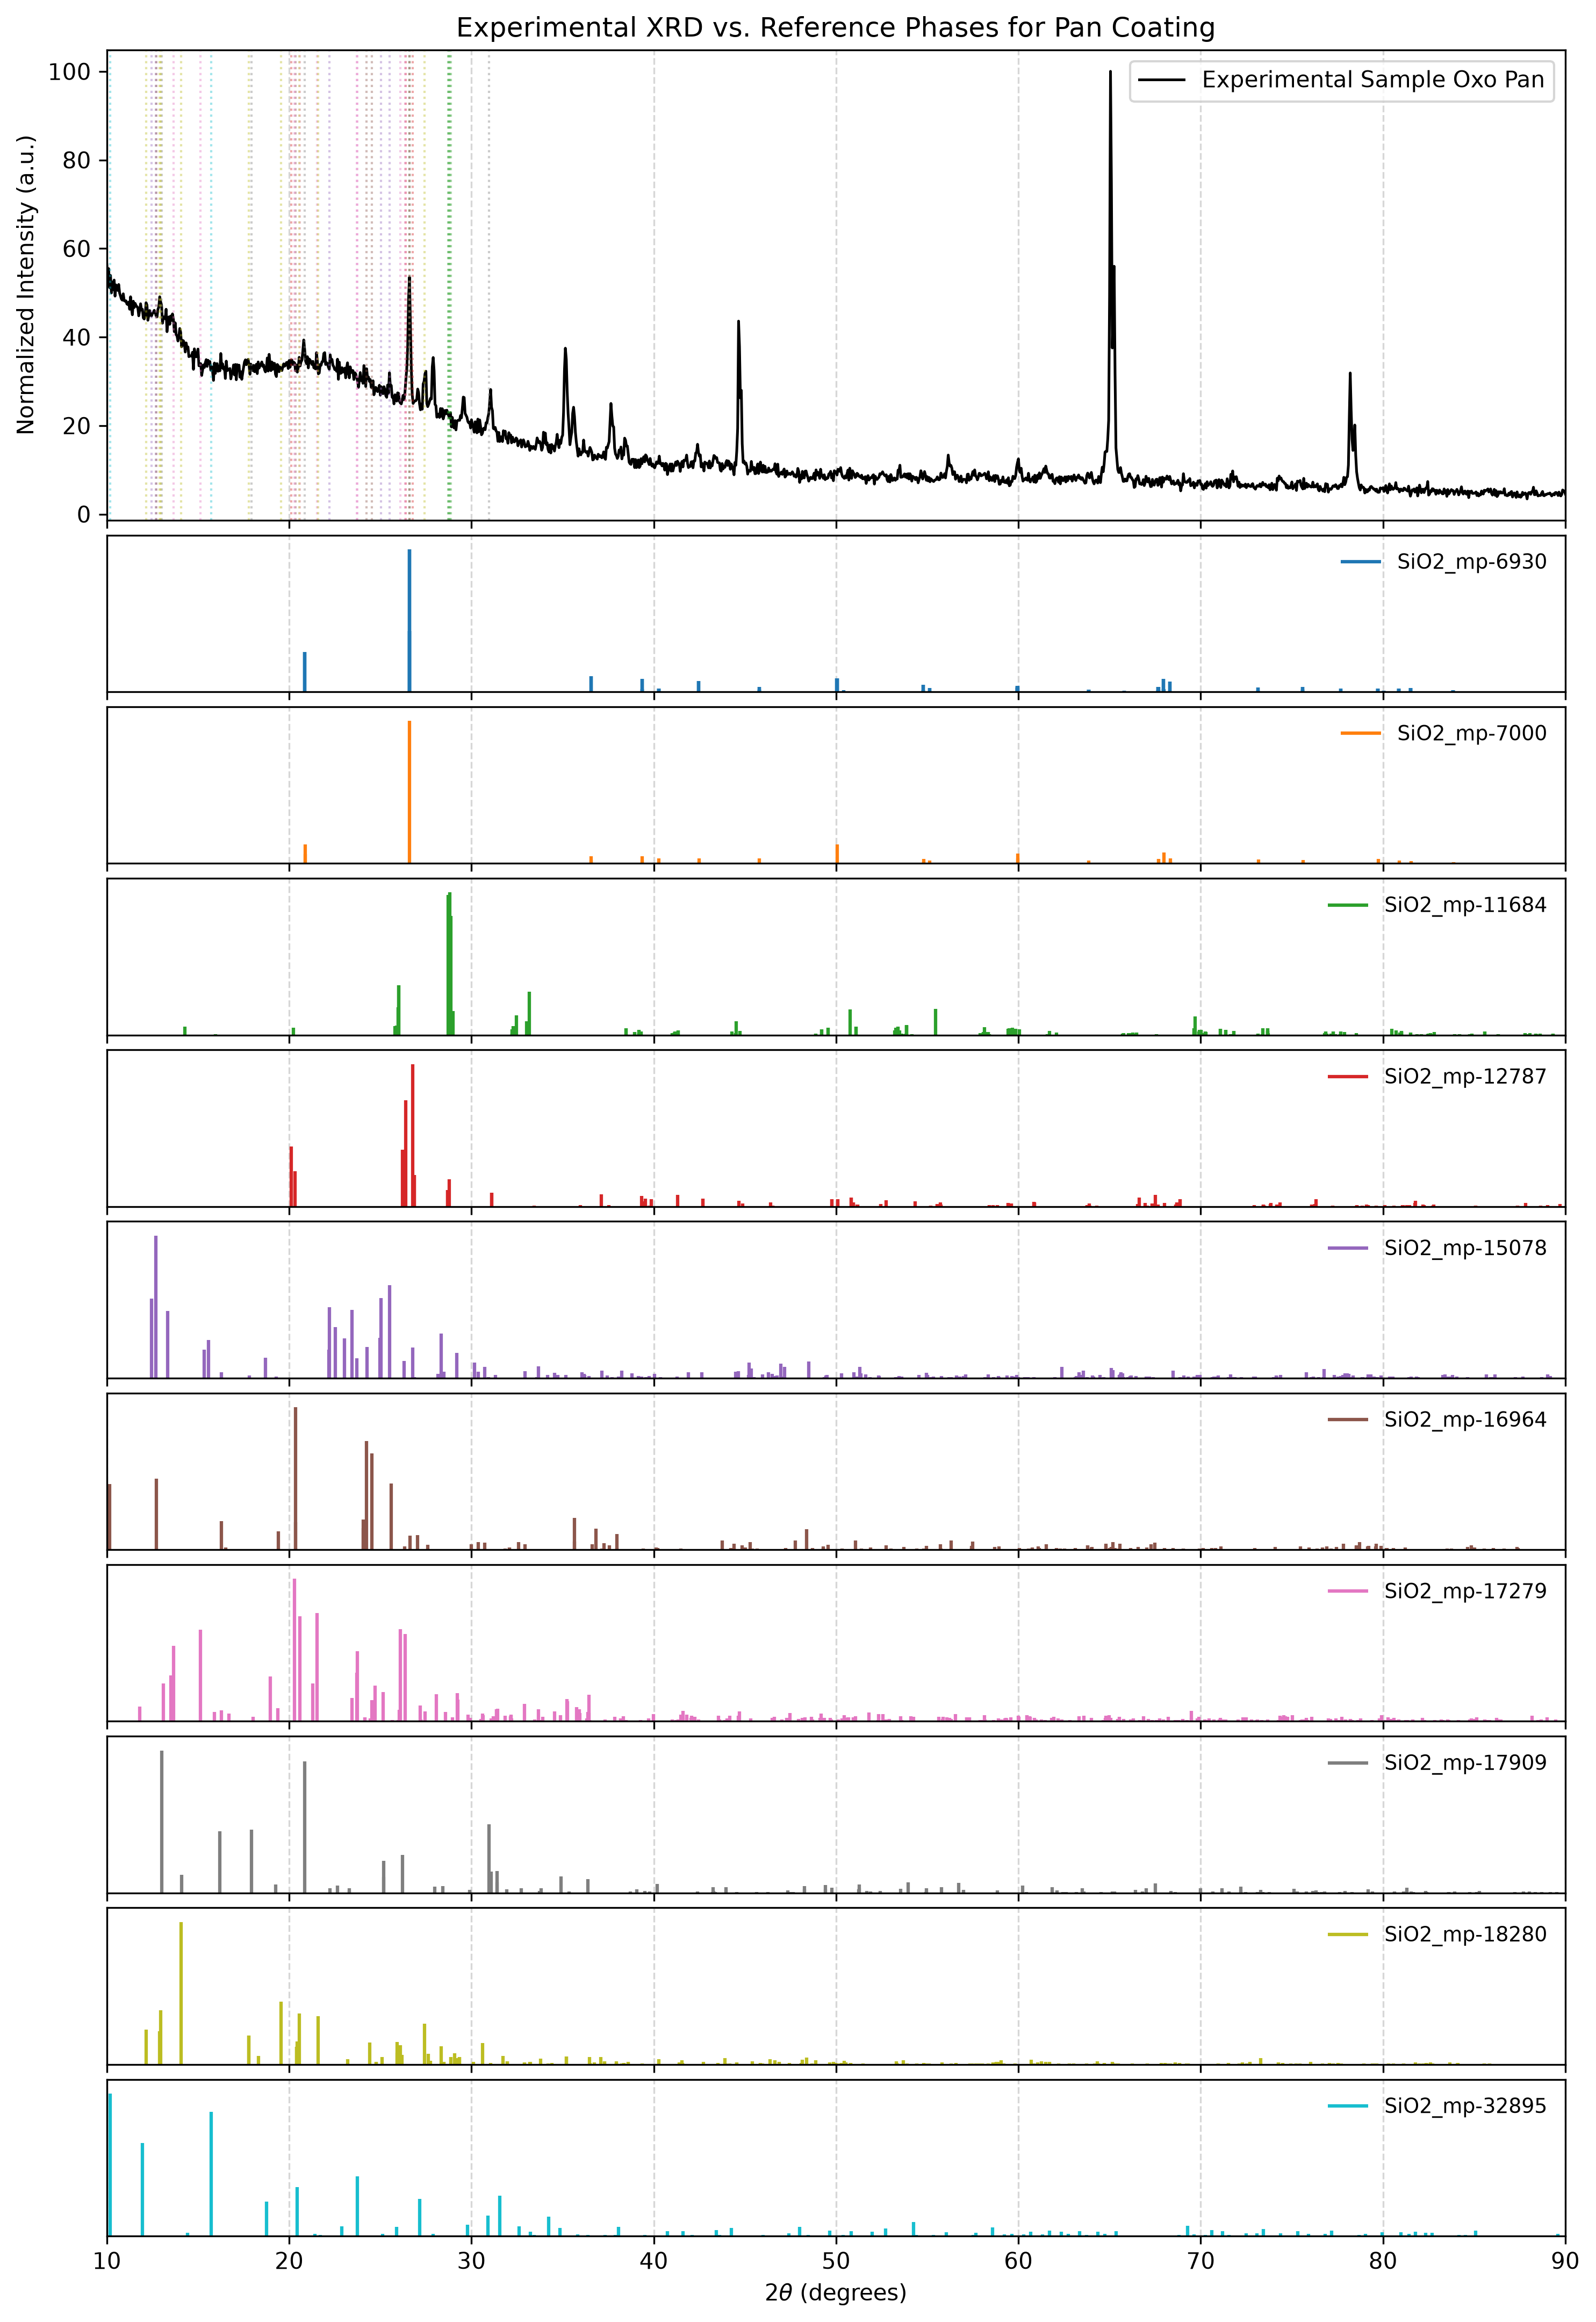

In [79]:
plot_from_dir('./cif_files/coating/', "Experimental XRD vs. Reference Phases for Pan Coating", 0.01)

/home/mhtoon/.conda/envs/MSE164L/lib/python3.15/site-packages/pymatgen/io/cif.py:1817: UserWarning: Issues encountered while parsing CIF: 2 fractional coordinates rounded to ideal values to avoid issues with finite precision.
  return parser.parse_structures(primitive=primitive)[0]


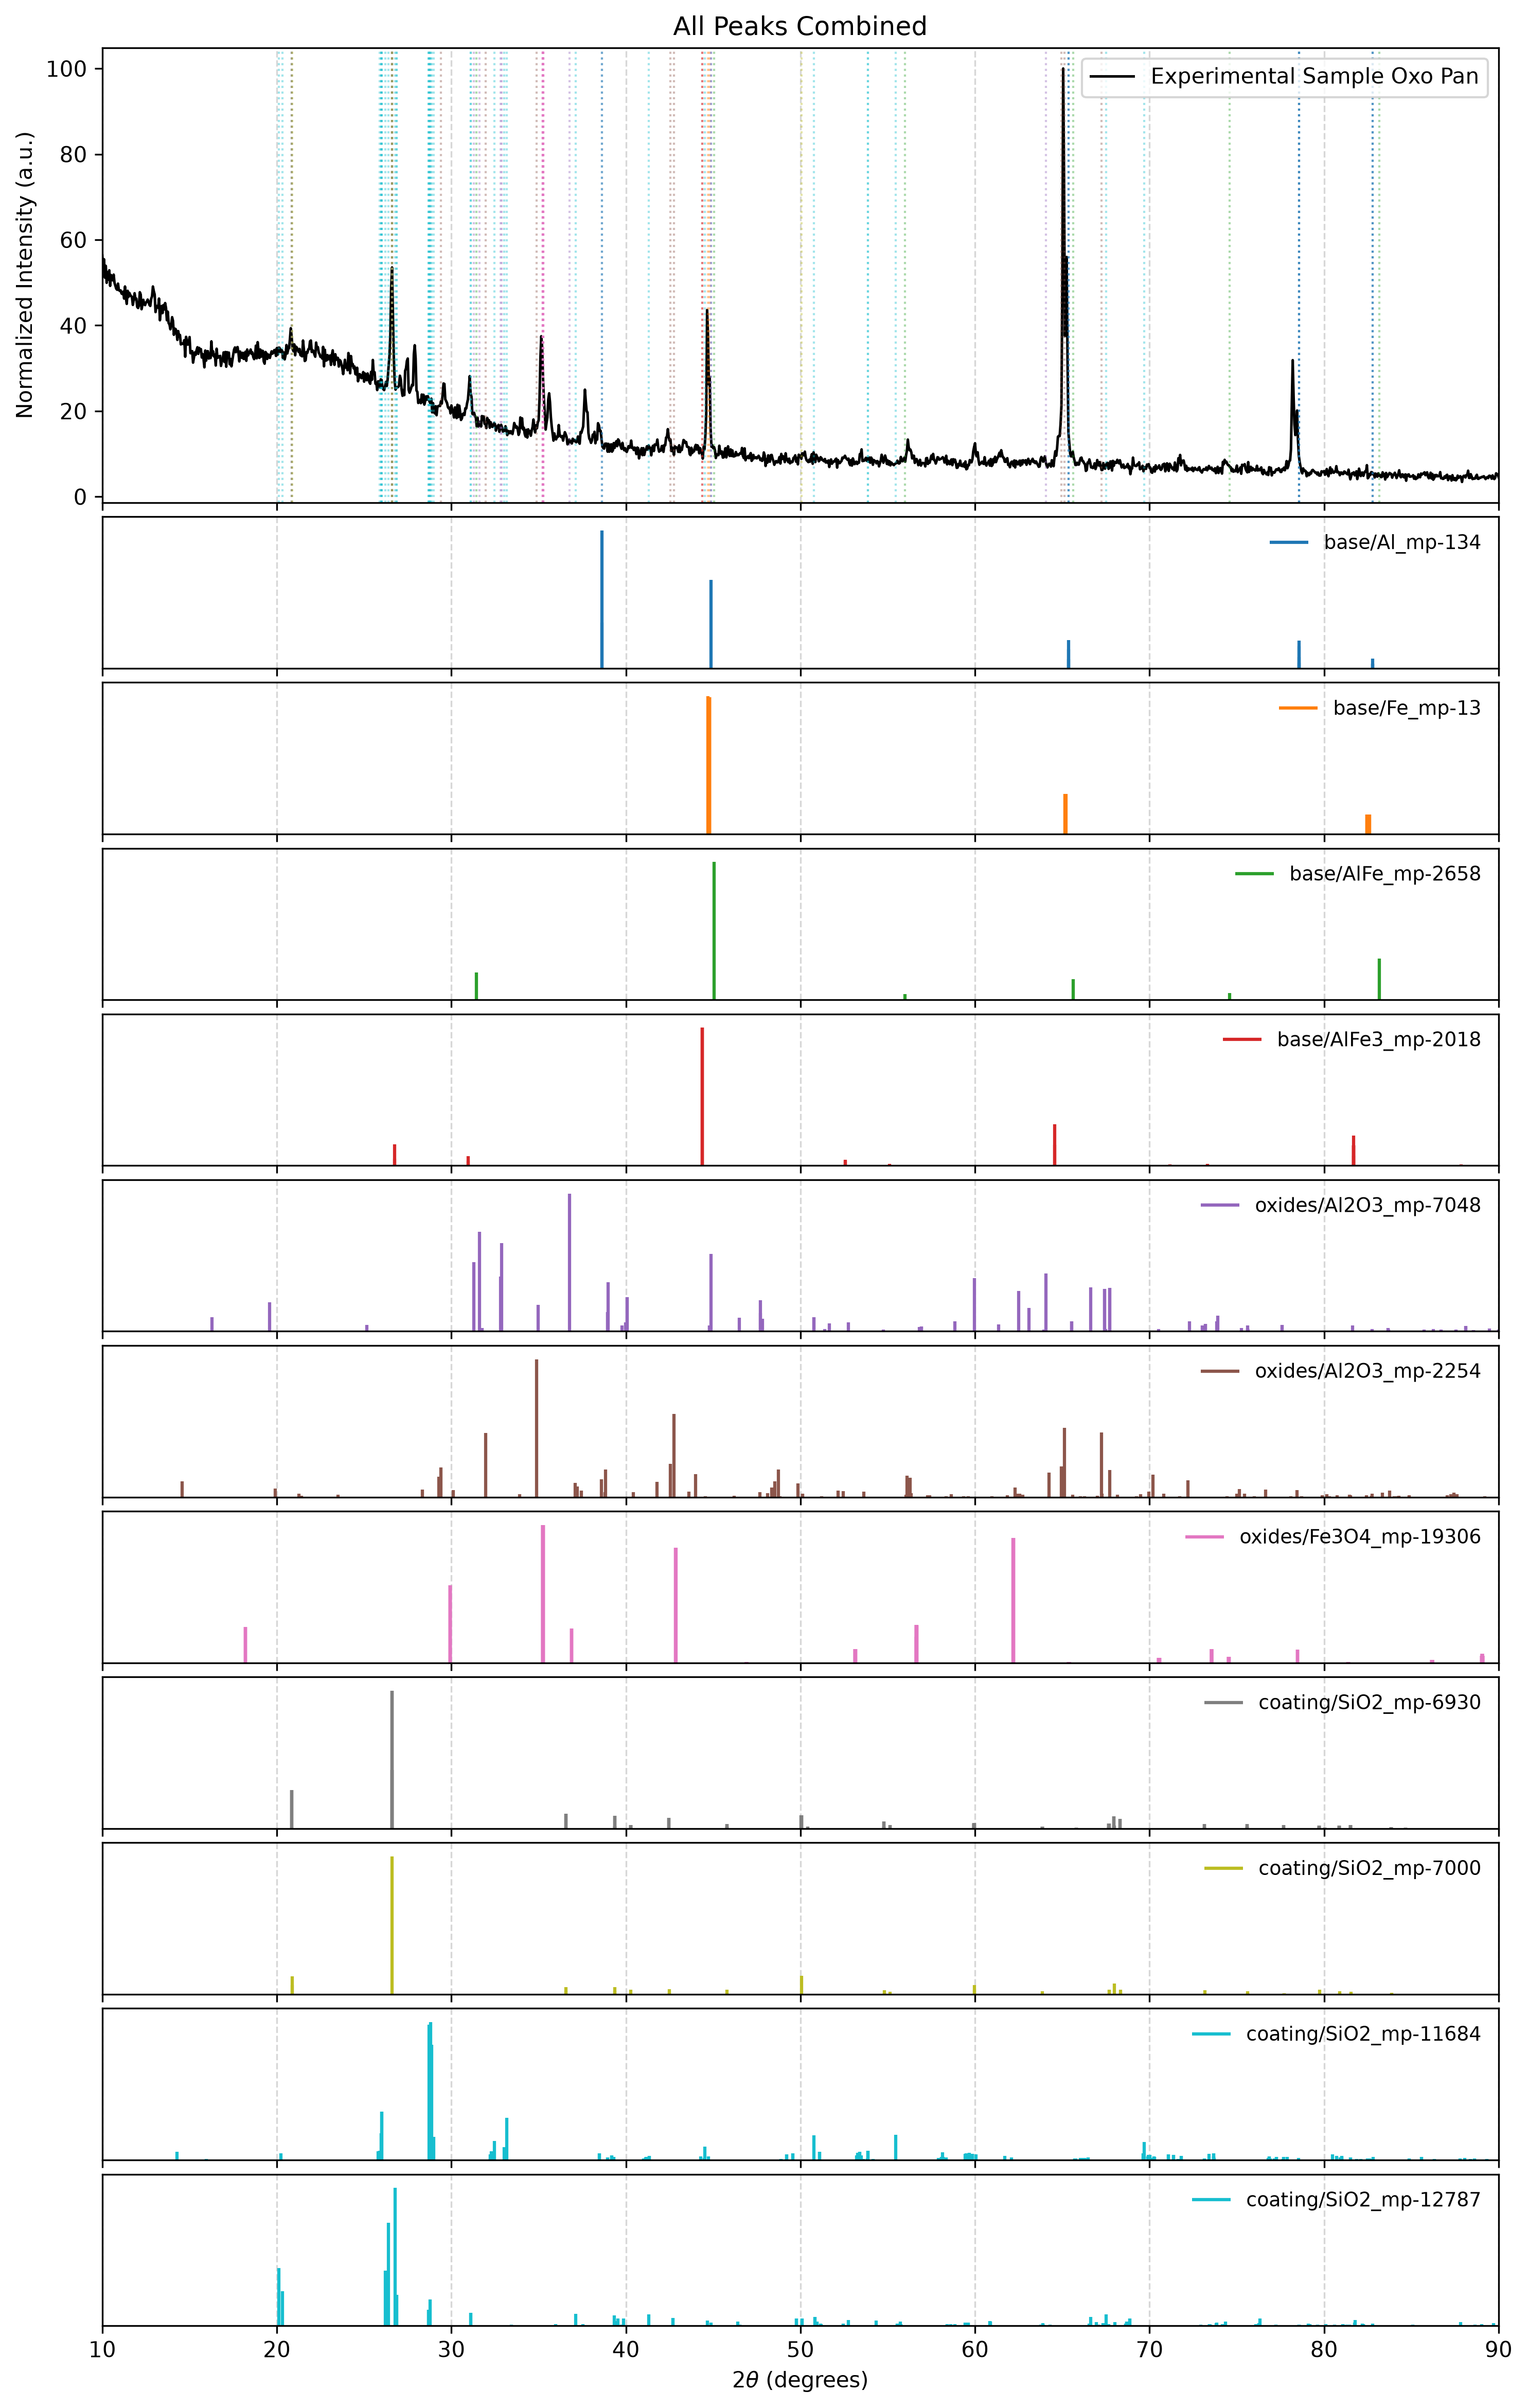

In [89]:
cifs = glob.glob('./cif_files/base/*.cif')+glob.glob('./cif_files/oxides/*.cif')+glob.glob('./cif_files/coating/*.cif')
structures = {}

for file in cifs:
    structures[file[:-4].replace('./cif_files/', '')] = Structure.from_file(file)
calculator = XRDCalculator(wavelength="CuKa")

two_theta_range=(10,90
                )
try:
    exp_data = data
    # Drop any non-numeric header rows if present
    exp_data = exp_data.apply(pd.to_numeric, errors='coerce').dropna()
    exp_2theta = exp_data.iloc[:, 0].values
    exp_intensity = exp_data.iloc[:, 1].values
except Exception as e:
    raise ValueError(f"Error reading experimental file: {e}. Check delimiter and header lines.")

# Filter experimental data to the specified 2-theta range and normalize to 100
mask = (exp_2theta >= two_theta_range[0]) & (exp_2theta <= two_theta_range[1])
exp_2theta = exp_2theta[mask]
exp_intensity = exp_intensity[mask]
exp_intensity_norm = (exp_intensity / np.max(exp_intensity)) * 100

num_refs = len(structures)
fig, axes = plt.subplots(
    nrows=num_refs + 1, 
    ncols=1, 
    figsize=(10, 2.5 + 1.2 * num_refs), 
    sharex=True,
    gridspec_kw={'height_ratios': [3] + [1] * num_refs}
)

if num_refs == 0:
    axes = [axes]

# 4. Plot Experimental Spectrum (Top Panel)
ax_exp = axes[0]
ax_exp.plot(exp_2theta, exp_intensity_norm, color='black', lw=1.2, label='Experimental Sample Oxo Pan')
ax_exp.set_ylabel("Normalized Intensity (a.u.)")
ax_exp.set_title("All Peaks Combined")
ax_exp.legend(loc="upper right")
ax_exp.grid(axis='x', linestyle='--', alpha=0.5)

# 5. Calculate and Plot Simulated Reference Stick Patterns
cmap = mpl.colormaps.get_cmap('tab10')

for idx, (label, struct) in enumerate(structures.items()):
    ax_ref = axes[idx + 1]
    pattern = calculator.get_pattern(struct, two_theta_range=two_theta_range)
    
    # Plot sticks for reference peaks
    ax_ref.vlines(pattern.x, 0, pattern.y, color=cmap(idx), lw=1.5, label=label)
    
    # Also plot vertical guide lines up into the experimental plot for top 5 strongest peaks
    if len(pattern.y) > 15:
        k = math.ceil(len(pattern.y)*0.05)
        top_peaks_idx = np.argsort(pattern.y)[-k:]
    else:
        top_peaks_idx = np.argsort(pattern.y)
    for peak_i in top_peaks_idx:
        ax_exp.axvline(pattern.x[peak_i], color=cmap(idx), linestyle=':', alpha=0.4, lw=1)

    ax_ref.set_ylim(0, 110)
    ax_ref.set_yticks([])
    ax_ref.legend(loc="upper right", frameon=False, fontsize=9)
    ax_ref.grid(axis='x', linestyle='--', alpha=0.5)

axes[-1].set_xlabel(r"$2\theta$ (degrees)")
axes[-1].set_xlim(two_theta_range)
plt.tight_layout()
plt.subplots_adjust(hspace=0.08)
plt.show()